# 07. Load vs mission

nb 06 fits the motor power against the **per-minute speed over ground**. That speed is noisy: waves, current, turns, GPS jitter. Here we use the speed of the **mission line** instead (nb 05, `data/mission_modes.csv`): every minute inside a line gets that line's median speed over ground. That averages the noise out, and it's also the speed the forecast will have (it doesn't know the minute-by-minute speed, only the mission).

Same rules as nb 06: **load = 10 W hotel + 22 W · Starlink + motor · k · vⁿ**, hotel and Starlink locked, no intercept, motor = 0 in MANUAL (armed or disarmed), 1 in AUTO and mode 17.

1. Each line on its own: propulsion vs speed, minute by minute and line by line
2. Fit k · v, k · v², k · v³ with the mission speed, compared with nb 06
3. Predicting the load: telemetry speed vs mission speed, real Starlink vs the schedule
4. One k for AUTO, one for mode 17

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load

# Starlink on/off: messages < 2 min apart = one session, ± 30 s (nb 06)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
df["starlink"] = False
for start, end in sessions.itertuples(index=False):
    df.loc[df.t.between(start - pd.Timedelta("30s"), end + pd.Timedelta("30s")), "starlink"] = True

HOTEL_W, STARLINK_W = 10, 22                                       # nb 06, locked
K_TEL = {"k·v": (1, 64.81), "k·v²": (2, 54.41), "k·v³": (3, 39.32)}  # nb 06 section 3b: fitted on the per-minute speed
GROUP_NAMES = ["MANUAL disarmed", "MANUAL armed", "AUTO", "mode 17"]
GROUP_COLORS = {"MANUAL disarmed": "#c7c7c7", "MANUAL armed": "#7f7f7f", "AUTO": "#2ca02c", "mode 17": "#d62728"}
MODEL_COLORS = {"k·v": "#2ca02c", "k·v²": "#9467bd", "k·v³": "#d62728"}
START, END = pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC")

def daily_axis(ax):
    ax.set_xlim(START, END)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# per-minute means (same as nb 06)
m = (df.dropna(subset=["P_load"]).set_index("t").resample("1min")
       .agg({"P_load": "mean", "groundspeed_ms": "mean", "starlink": "max"})
       .dropna(subset=["P_load"]).reset_index())
m["starlink"] = m.starlink.astype(bool)
m["P_prop"] = m.P_load - HOTEL_W - STARLINK_W * m.starlink

# the mission: each minute gets its line
mission = pd.read_csv("../data/mission_modes.csv", parse_dates=["from", "to"])
mission["group"] = np.where(mission["mode"] == "MANUAL", np.where(mission.armed, "MANUAL armed", "MANUAL disarmed"), mission["mode"])
mission["v_line"] = mission["SOG (m/s)"]
idx = np.searchsorted(mission["from"].values, m.t.values, side="right") - 1
inside = (idx >= 0) & (m.t.values < mission["to"].values[idx.clip(0)])
m["line"] = np.where(inside, mission["#"].values[idx.clip(0)], -1)
m = m[m.line >= 0].merge(mission[["#", "group", "v_line", "hours"]], left_on="line", right_on="#").drop(columns="#")
m["motor"] = m.group.isin(["AUTO", "mode 17"]).astype(int)
print(f"{len(m)} minutes with a load reading, inside {m.line.nunique()} of {len(mission)} mission lines")
print("motor-on lines with no speed:", mission[mission.group.isin(["AUTO", "mode 17"]) & mission.v_line.isna()]["#"].tolist())

5898 minutes with a load reading, inside 80 of 95 mission lines
motor-on lines with no speed: []


## 1. Each line on its own

Motor on only (AUTO and mode 17). **Left:** what nb 06 fits, one dot per minute at its own speed. **Right:** the same minutes, but each line collapsed to **one dot**: its median speed (x) against its mean propulsion (y); dot area = minutes with a load reading. The faint dots behind are the minutes again, now placed at the line's speed (so each line is a vertical stripe).

Propulsion = load − 10 W − 22 W · Starlink (real Starlink).

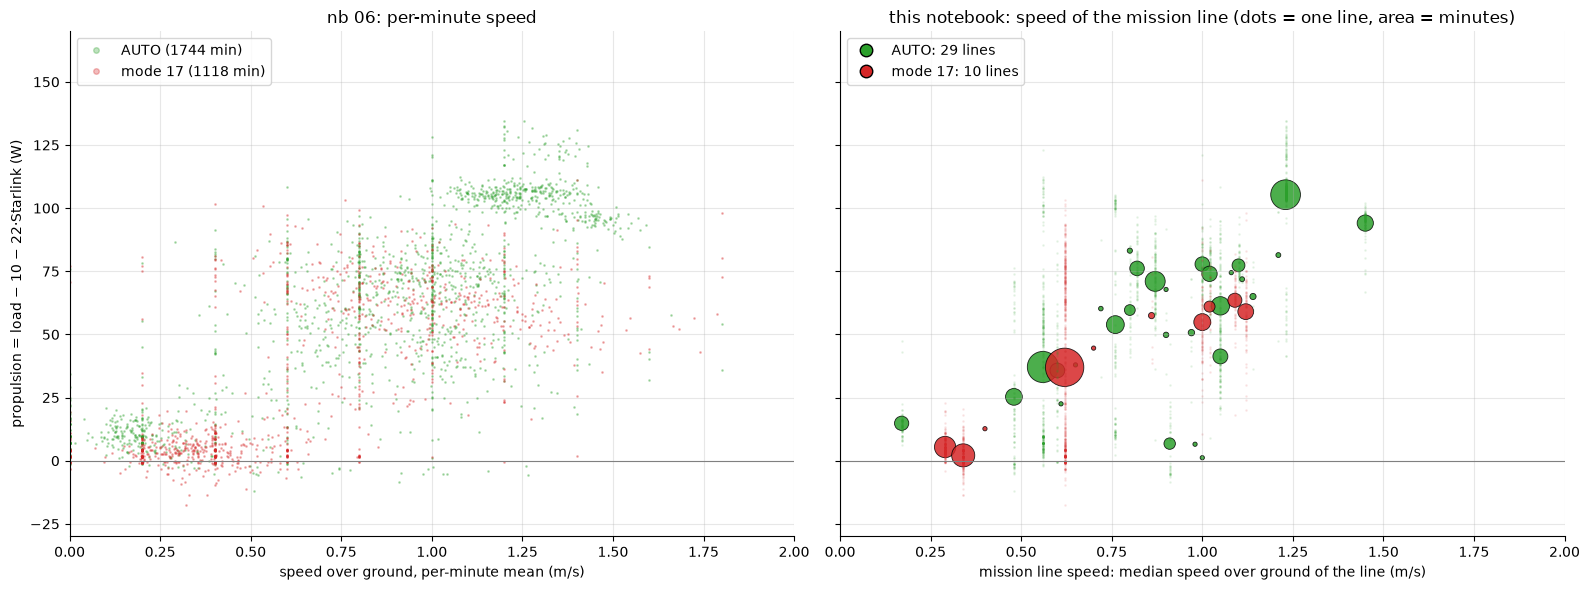

lines by speed (v_line = median speed of the line, sog_mean = mean of its minutes with a load reading):


,group,v_line,P_prop,minutes,sog_mean
line,,,,,
24,AUTO,0.17,14.82,65,0.18
37,mode 17,0.29,5.43,151,0.29
39,mode 17,0.34,2.12,179,0.32
40,mode 17,0.40,12.67,1,0.30
57,AUTO,0.48,25.28,92,0.56
26,AUTO,0.56,37.11,330,0.56
47,AUTO,0.60,35.73,70,0.59
49,AUTO,0.61,22.52,1,0.60
41,mode 17,0.62,36.98,503,0.64


In [2]:
on = m[m.motor == 1].dropna(subset=["v_line"])
per_line = on.groupby("line").agg(group=("group", "first"), v_line=("v_line", "first"), P_prop=("P_prop", "mean"),
                                  minutes=("P_prop", "size"), sog_mean=("groundspeed_ms", "mean"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True, sharex=True)
for grp in ["AUTO", "mode 17"]:
    s = on[on.group == grp]
    a1.plot(s.groundspeed_ms, s.P_prop, ".", ms=2, alpha=0.3, color=GROUP_COLORS[grp], label=f"{grp} ({len(s)} min)")
    a2.plot(s.v_line, s.P_prop, ".", ms=2, alpha=0.08, color=GROUP_COLORS[grp])
    l = per_line[per_line.group == grp]
    a2.scatter(l.v_line, l.P_prop, s=8 + 1.5 * l.minutes, color=GROUP_COLORS[grp], edgecolor="k", lw=0.6, alpha=0.85,
               label=f"{grp}: {len(l)} lines")
for a in (a1, a2):
    a.axhline(0, color="grey", lw=0.8); a.set_xlim(0, 2); a.set_ylim(-30, 170)
a1.legend(loc="upper left", markerscale=4)
a2.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=9, mec="k", color=GROUP_COLORS[g],
                              label=f"{g}: {(per_line.group == g).sum()} lines") for g in ["AUTO", "mode 17"]], loc="upper left")
a1.set_xlabel("speed over ground, per-minute mean (m/s)"); a2.set_xlabel("mission line speed: median speed over ground of the line (m/s)")
a1.set_ylabel("propulsion = load − 10 − 22·Starlink (W)")
a1.set_title("nb 06: per-minute speed"); a2.set_title("this notebook: speed of the mission line (dots = one line, area = minutes)")
plt.tight_layout(); plt.show()
print("lines by speed (v_line = median speed of the line, sog_mean = mean of its minutes with a load reading):")
per_line.sort_values("v_line").round(2)

## 2. Fit with the mission speed

Least squares of propulsion against **v_line**ⁿ, over every motor-on minute (so a line counts by how many minutes it has), hotel and Starlink locked, no intercept. Same three shapes as nb 06.

Two scores per fit:
- **per minute:** R² and residual spread over the minutes, comparable with nb 06 (but each line's own wobble is now error, since v_line is flat inside a line)
- **per line:** R² of the line means, i.e. how well the curve follows the line dots on the right of section 1

2862 motor-on minutes in 39 lines


,"k, mission speed",std error,"k, per-minute speed (nb 06)",R² per minute,residual std (W),median |residual| (W),R² per line (minute-weighted)
model,,,,,,,
k·v,66.82,0.59,64.81,0.48,26.39,21.16,0.76
k·v²,63.32,0.59,54.41,0.43,27.38,16.65,0.67
k·v³,52.06,0.61,39.32,0.20,30.37,13.85,0.31


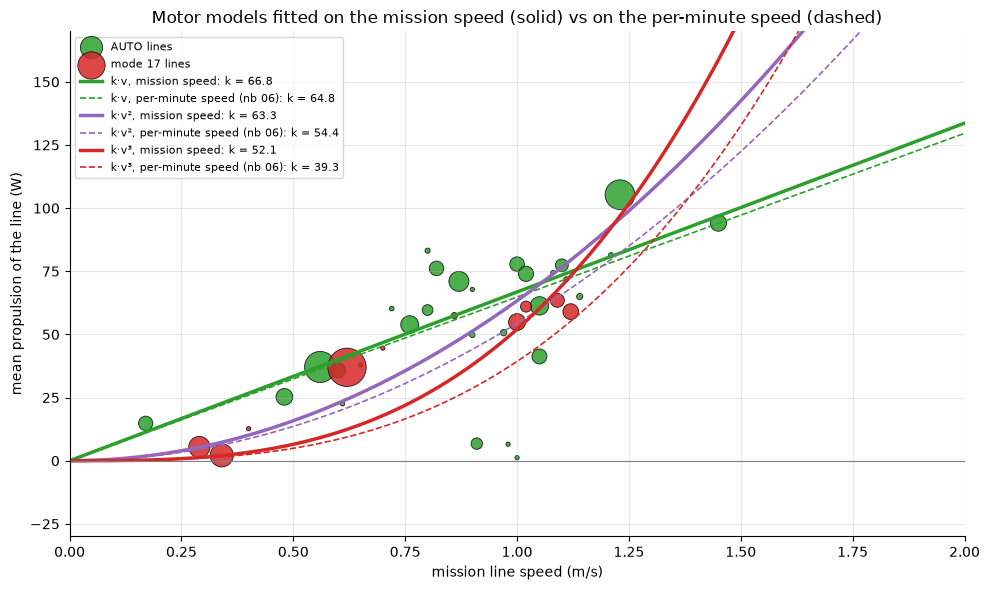

In [3]:
y = on.P_prop.values
K_MIS, rows = {}, []
for name, (n, k_tel) in K_TEL.items():
    X = (on.v_line.values ** n)[:, None]
    kn = np.linalg.lstsq(X, y, rcond=None)[0][0]
    r = y - kn * X[:, 0]
    se = np.sqrt((r ** 2).sum() / (len(y) - 1) / (X[:, 0] ** 2).sum())
    pl = per_line.P_prop - kn * per_line.v_line ** n
    w = per_line.minutes
    r2_line = 1 - (w * pl ** 2).sum() / (w * (per_line.P_prop - np.average(per_line.P_prop, weights=w)) ** 2).sum()
    K_MIS[name] = (n, kn)
    rows.append({"model": name, "k, mission speed": kn, "std error": se, "k, per-minute speed (nb 06)": k_tel,
                 "R² per minute": 1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum(), "residual std (W)": r.std(),
                 "median |residual| (W)": np.median(np.abs(r)), "R² per line (minute-weighted)": r2_line})
fits = pd.DataFrame(rows).set_index("model")
print(f"{len(on)} motor-on minutes in {len(per_line)} lines")
display(fits.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
for grp in ["AUTO", "mode 17"]:
    l = per_line[per_line.group == grp]
    ax.scatter(l.v_line, l.P_prop, s=8 + 1.5 * l.minutes, color=GROUP_COLORS[grp], edgecolor="k", lw=0.6, alpha=0.85, label=f"{grp} lines")
vv = np.linspace(0, 2, 200)
for name, (n, kn) in K_MIS.items():
    ax.plot(vv, kn * vv ** n, lw=2.5, color=MODEL_COLORS[name], label=f"{name}, mission speed: k = {kn:.1f}")
    ax.plot(vv, K_TEL[name][1] * vv ** n, lw=1.2, ls="--", color=MODEL_COLORS[name], label=f"{name}, per-minute speed (nb 06): k = {K_TEL[name][1]:.1f}")
ax.axhline(0, color="grey", lw=0.8); ax.set_xlim(0, 2); ax.set_ylim(-30, 170)
ax.set_xlabel("mission line speed (m/s)"); ax.set_ylabel("mean propulsion of the line (W)")
ax.set_title("Motor models fitted on the mission speed (solid) vs on the per-minute speed (dashed)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 3. Predicting the load

Four predictions of the per-minute load, all with the k·v shape (best in nb 06) unless stated, scored on the same minutes. Error = actual − predicted.

| prediction | speed | Starlink | k |
| --- | --- | --- | --- |
| **telemetry** (nb 06 section 4) | per-minute speed over ground | real | 64.81 (nb 06) |
| **mission, nb 06 k** | mission line speed | real | 64.81 (nb 06) |
| **mission, refit k** | mission line speed | real | refit here (section 2) |
| **mission + schedule** | mission line speed | schedule (nb 04) | refit here |

The last one is what a forecast can actually know: the mission and the Starlink schedule, nothing measured.

In [4]:
sl_plan = pd.read_csv("../data/mission_starlink.csv", parse_dates=["from", "to"], keep_default_na=False).rename(columns={"from": "start"})
def starlink_schedule(ts):
    ts = pd.DatetimeIndex(ts); sl = np.zeros(len(ts))
    for r in sl_plan.itertuples():
        inside = (ts >= r.start) & (ts < r.to)
        if r.duty > 0:
            sl[inside] = r.duty
        elif r.wake_hours:
            after = (ts - ts.floor("h")).total_seconds() / 60 - 47
            sl[inside & ts.hour.isin([int(h) for h in r.wake_hours.split()]) & (after >= 0) & (after < r.on_min)] = 1
    return sl

m["sl_plan"] = starlink_schedule(m.t)
v_line = m.v_line.fillna(0).values
k_tel, k_mis = K_TEL["k·v"][1], K_MIS["k·v"][1]
PRED = {"telemetry": HOTEL_W + STARLINK_W * m.starlink + m.motor * k_tel * m.groundspeed_ms.fillna(0),
        "mission, nb 06 k": HOTEL_W + STARLINK_W * m.starlink + m.motor * k_tel * v_line,
        "mission, refit k": HOTEL_W + STARLINK_W * m.starlink + m.motor * k_mis * v_line,
        "mission + schedule": HOTEL_W + STARLINK_W * m.sl_plan + m.motor * k_mis * v_line}
for name, (n, kn) in K_MIS.items():
    if n > 1:
        PRED[f"mission, refit {name}"] = HOTEL_W + STARLINK_W * m.starlink + m.motor * kn * v_line ** n
PRED_STYLE = {"telemetry": dict(color="grey", lw=1), "mission, nb 06 k": dict(color="#1f77b4", lw=1, ls="--"),
              "mission, refit k": dict(color="#1f77b4", lw=1.5), "mission + schedule": dict(color="#d62728", lw=1.5)}

def scores(e):
    return pd.Series({"mean error (W)": e.mean(), "RMSE (W)": np.sqrt((e ** 2).mean()), "median |error| (W)": e.abs().median(), "max |error| (W)": e.abs().max()})
errs = {n: m.P_load - p for n, p in PRED.items()}
print(f"{len(m)} minutes")
display(pd.DataFrame({n: scores(e) for n, e in errs.items()}).T.round(1))
print("by mode: mean error (W) | RMSE (W)")
pd.concat({"mean error (W)": pd.DataFrame({n: e.groupby(m.group).mean() for n, e in errs.items()}),
           "RMSE (W)": pd.DataFrame({n: e.groupby(m.group).apply(lambda x: np.sqrt((x ** 2).mean())) for n, e in errs.items()})}).reindex(GROUP_NAMES, level=1).round(1)

5898 minutes


,mean error (W),RMSE (W),median |error| (W),max |error| (W)
telemetry,0.3,18.0,5.5,122.2
"mission, nb 06 k",0.3,19.6,5.6,97.0
"mission, refit k",-0.4,19.5,5.6,97.0
mission + schedule,5.6,22.7,9.0,115.6
"mission, refit k·v²",3.0,20.5,5.6,103.0
"mission, refit k·v³",6.8,23.9,5.5,113.7


by mode: mean error (W) | RMSE (W)


telemetry  mission, nb 06 k  mission, refit k  \
               group                                                            
mean error (W) MANUAL disarmed        0.3               0.3               0.3   
               MANUAL armed           1.3               1.3               1.3   
               AUTO                   5.0               4.9               3.2   
               mode 17               -9.4              -8.8             -10.1   
RMSE (W)       MANUAL disarmed        6.1               6.1               6.1   
               MANUAL armed           9.7               9.7               9.7   
               AUTO                  23.8              27.0              26.6   
               mode 17               24.4              25.8              26.2   

                                mission + schedule  mission, refit k·v²  \
               group                                                      
mean error (W) MANUAL disarmed                 4.1                  0.3   
               MANUAL armed                    4.3                  1.3   
               AUTO                           11.9                  7.1   
               mode 17                        -0.7                  1.9   
RMSE (W)       MANUAL disarmed                11.0                  6.1   
               MANUAL armed                   13.6                  9.7   
               AUTO                           31.0                 29.0   
               mode 17                        27.4                 25.9   

                                mission, refit k·v³  
               group                                 
mean error (W) MANUAL disarmed                  0.3  
               MANUAL armed                     1.3  
               AUTO                            14.0  
               mode 17                         11.0  
RMSE (W)       MANUAL disarmed                  6.1  
               MANUAL armed                     9.7  
               AUTO                            35.3  
               mode 17                         29.1

**Over the mission.** Hourly means of the measured load (black) and the main predictions. Bottom: per line, mean error of each prediction (one dot per motor-on line, at the line's start).

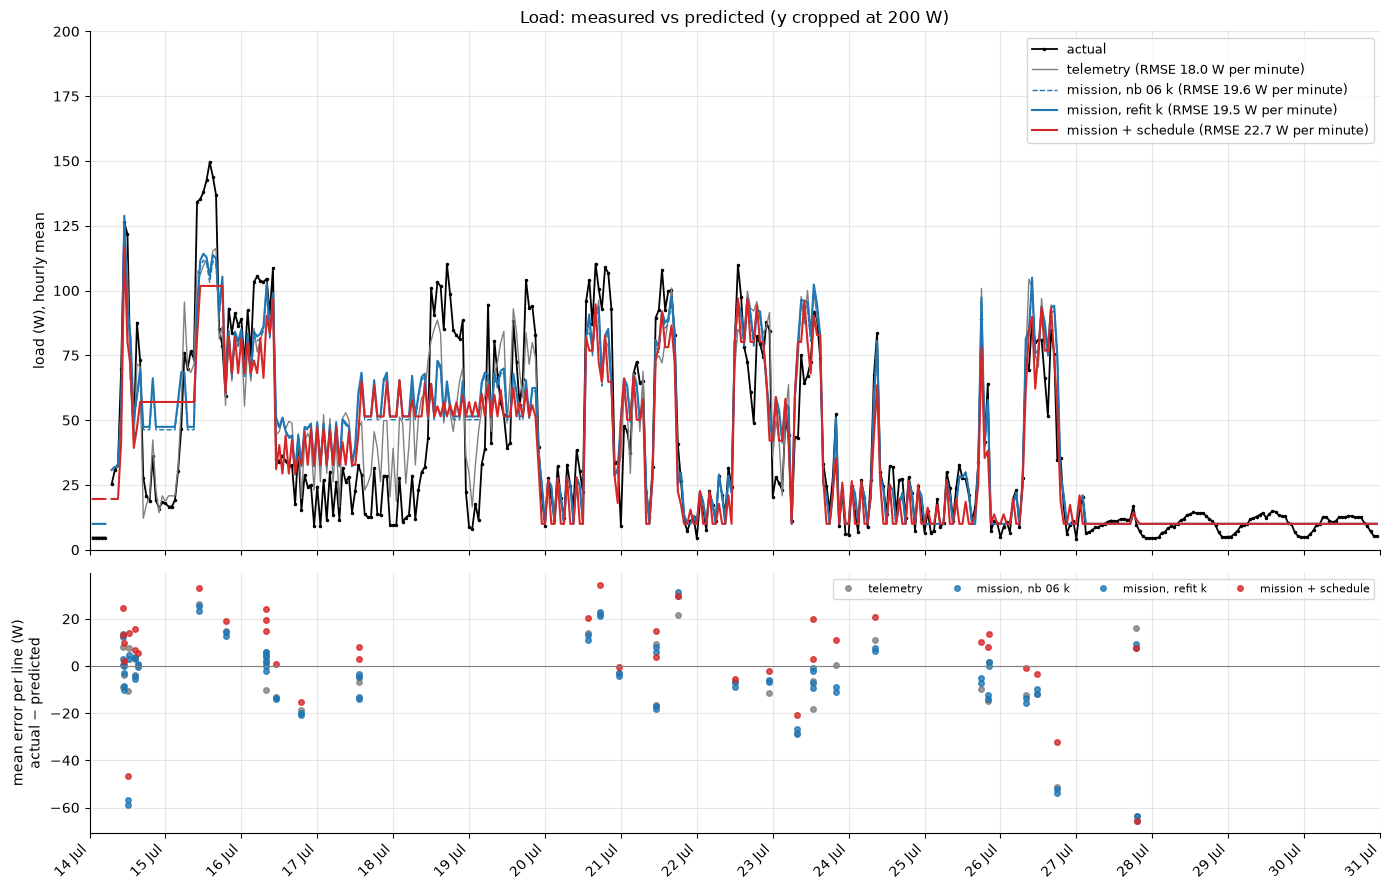

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
actual,66.0,107.0,60.0,25.0,68.0,59.0,66.0,51.0,45.0,50.0,30.0,35.0,53.0,9.0,10.0,10.0,10.0
telemetry,61.0,92.0,62.0,44.0,66.0,64.0,55.0,49.0,48.0,60.0,28.0,35.0,63.0,11.0,10.0,10.0,10.0
"mission, nb 06 k",63.0,90.0,63.0,52.0,63.0,58.0,55.0,49.0,45.0,61.0,28.0,34.0,63.0,11.0,10.0,10.0,10.0
"mission, refit k",64.0,92.0,64.0,53.0,64.0,59.0,56.0,50.0,46.0,62.0,28.0,34.0,65.0,11.0,10.0,10.0,10.0
mission + schedule,53.0,84.0,53.0,47.0,55.0,52.0,48.0,44.0,41.0,55.0,23.0,25.0,54.0,11.0,10.0,10.0,10.0


In [5]:
hh = pd.concat([m.set_index("t").P_load] + [p.set_axis(m.t).rename(n) for n, p in PRED.items() if n in PRED_STYLE], axis=1).resample("1h").mean()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax.plot(hh.index, hh.P_load, ".-", ms=3, lw=1.3, color="k", label="actual")
for n, st in PRED_STYLE.items():
    ax.plot(hh.index, hh[n], label=f"{n} (RMSE {np.sqrt((errs[n] ** 2).mean()):.1f} W per minute)", **st)
ax.set_ylim(0, 200); ax.set_ylabel("load (W), hourly mean"); ax.legend(fontsize=9, loc="upper right")
ax.set_title("Load: measured vs predicted (y cropped at 200 W)")
starts = mission.set_index("#")["from"]
for n, st in PRED_STYLE.items():
    le = errs[n][m.motor == 1].groupby(m.line[m.motor == 1]).mean()
    ax2.plot(starts.reindex(le.index), le.values, "o", ms=4, color=st["color"], alpha=0.8, label=n)
ax2.axhline(0, color="grey", lw=0.8); ax2.set_ylabel("mean error per line (W)\nactual − predicted")
ax2.legend(fontsize=8, ncol=4, loc="upper right")
daily_axis(ax2)
plt.tight_layout(); plt.show()

d = pd.concat([m.P_load] + [p.rename(n) for n, p in PRED.items() if n in PRED_STYLE], axis=1).groupby(m.t.dt.floor("D")).mean()
d.set_axis(d.index.strftime("%d %b")).rename(columns={"P_load": "actual"}).round(0).T

**What we see:**
- **The mission speed removes most of the scatter.** One dot per line follows the k·v line well: **R² 0.76 over the line means**, against 0.58 per minute in nb 06.
- **k barely moves for k·v: 66.8 vs 64.8 W per m/s.** The steeper shapes change more (k·v³: 52 vs 39), because averaging takes out the speed spikes that pulled their k down.
- **k·v is still the best shape**, on the lines (R² 0.76 vs 0.67 for k·v² and 0.31 for k·v³) and on the minutes.
- **Predicting per-minute load, the mission speed is almost as good as the real speed:** RMSE 19.5 W vs 18.0 W from telemetry, the same mean error (−0.4 vs +0.3 W) and median (5.6 vs 5.5 W). The worst minute gets smaller (97 vs 122 W): no more speed spikes.
- **The schedule costs more than the speed does.** Swapping real Starlink for the schedule takes RMSE from 19.5 to 22.7 W and the bias from −0.4 to +5.6 W. That's the 60 extra sessions switched on from shore, and the 0.44 duty cycle on the deployment day.
- **What's left is mode.** AUTO is still under-predicted (+3 W) and mode 17 over-predicted (−10 W) with one shared k. In section 1 the mode-17 lines (red) sit under the AUTO lines at the same speed.
- **A few AUTO lines sit near 0 W at 0.9–1.0 m/s.** They're short (1–20 min), probably drifting with the current while in AUTO.

**Hypothesis:** a separate k for AUTO and mode 17 removes most of the remaining per-mode bias. *Test:* fit k·v on the line speed per mode and compare the per-mode mean errors with the table above.


## 4. One k for AUTO, one for mode 17

Same fit as section 2, mission line speed, hotel and Starlink locked, no intercept, but **each mode gets its own k**. All three shapes are fitted per mode for the table; the plot and the predictions use k·v.

k  std error  k, both modes (section 2)  minutes  lines  \
mode    model                                                                
AUTO    k·v    71.30       0.68                      66.82     1744     29   
        k·v²   64.17       0.69                      63.32     1744     29   
        k·v³   51.41       0.70                      52.06     1744     29   
mode 17 k·v    54.42       1.06                      66.82     1118     10   
        k·v²   59.80       1.24                      63.32     1118     10   
        k·v³   55.89       1.39                      52.06     1118     10   

               mean residual (W)  R² per minute  R² per line  
mode    model                                                 
AUTO    k·v                -0.77           0.46         0.71  
        k·v²                6.40           0.34         0.53  
        k·v³               14.64           0.02         0.03  
mode 17 k·v                -2.17           0.38         0.85  
        k·v²                3.65           0.32         0.73  
        k·v³                9.43           0.15         0.33

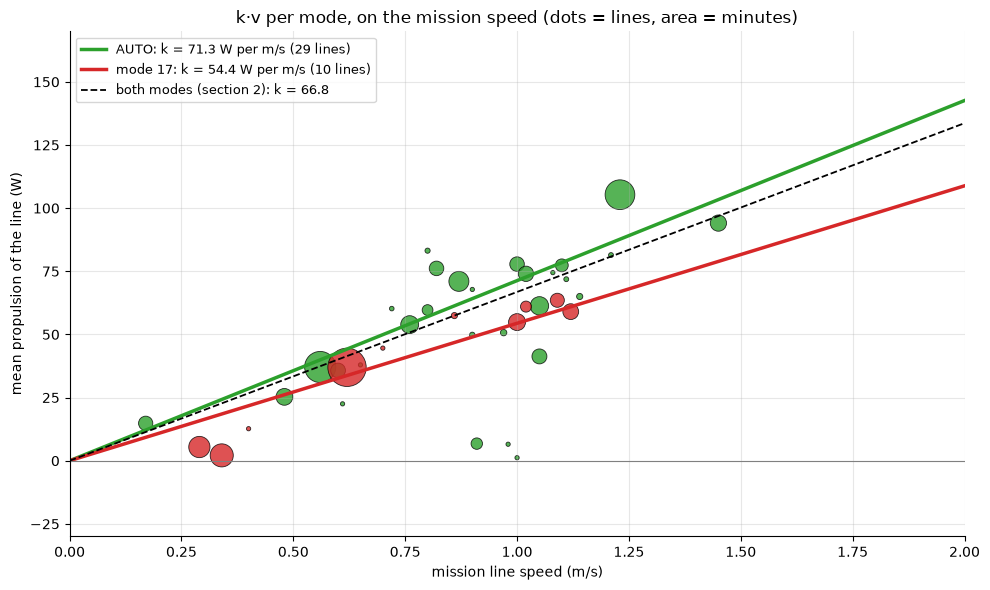

In [6]:
rows, K_MODE = [], {}
for grp in ["AUTO", "mode 17"]:
    s = on[on.group == grp]; ys = s.P_prop.values
    pls = per_line[per_line.group == grp]; w = pls.minutes
    for name, (n, _) in K_TEL.items():
        X = s.v_line.values ** n
        kn = (X * ys).sum() / (X ** 2).sum()
        r = ys - kn * X
        se = np.sqrt((r ** 2).sum() / (len(ys) - 1) / (X ** 2).sum())
        pl = pls.P_prop - kn * pls.v_line ** n
        K_MODE[(grp, name)] = kn
        rows.append({"mode": grp, "model": name, "k": kn, "std error": se, "k, both modes (section 2)": K_MIS[name][1],
                     "minutes": len(ys), "lines": len(pls), "mean residual (W)": r.mean(),
                     "R² per minute": 1 - (r ** 2).sum() / ((ys - ys.mean()) ** 2).sum(),
                     "R² per line": 1 - (w * pl ** 2).sum() / (w * (pls.P_prop - np.average(pls.P_prop, weights=w)) ** 2).sum()})
display(pd.DataFrame(rows).set_index(["mode", "model"]).round(2))

fig, ax = plt.subplots(figsize=(10, 6))
vv = np.linspace(0, 2, 200)
for grp in ["AUTO", "mode 17"]:
    l = per_line[per_line.group == grp]
    ax.scatter(l.v_line, l.P_prop, s=8 + 1.5 * l.minutes, color=GROUP_COLORS[grp], edgecolor="k", lw=0.6, alpha=0.8)
    kk = K_MODE[(grp, "k·v")]
    ax.plot(vv, kk * vv, lw=2.5, color=GROUP_COLORS[grp], label=f"{grp}: k = {kk:.1f} W per m/s ({len(l)} lines)")
ax.plot(vv, K_MIS["k·v"][1] * vv, lw=1.3, ls="--", color="k", label=f"both modes (section 2): k = {K_MIS['k·v'][1]:.1f}")
ax.axhline(0, color="grey", lw=0.8); ax.set_xlim(0, 2); ax.set_ylim(-30, 170)
ax.set_xlabel("mission line speed (m/s)"); ax.set_ylabel("mean propulsion of the line (W)")
ax.set_title("k·v per mode, on the mission speed (dots = lines, area = minutes)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

**Predictions with k per mode** (k·v), next to the shared-k ones from section 3. Error = actual − predicted, same minutes.

In [7]:
k_by_min = np.select([m.group == "AUTO", m.group == "mode 17"], [K_MODE[("AUTO", "k·v")], K_MODE[("mode 17", "k·v")]], 0.0)
PRED["mission, k per mode"] = HOTEL_W + STARLINK_W * m.starlink + m.motor * k_by_min * v_line
PRED["mission + schedule, k per mode"] = HOTEL_W + STARLINK_W * m.sl_plan + m.motor * k_by_min * v_line
show = ["telemetry", "mission, refit k", "mission, k per mode", "mission + schedule", "mission + schedule, k per mode"]
errs = {n: m.P_load - PRED[n] for n in show}
display(pd.DataFrame({n: scores(e) for n, e in errs.items()}).T.round(1))
print("by mode:")
pd.concat({"mean error (W)": pd.DataFrame({n: e.groupby(m.group).mean() for n, e in errs.items()}),
           "RMSE (W)": pd.DataFrame({n: e.groupby(m.group).apply(lambda x: np.sqrt((x ** 2).mean())) for n, e in errs.items()})}).reindex(GROUP_NAMES, level=1).round(1)

,mean error (W),RMSE (W),median |error| (W),max |error| (W)
telemetry,0.3,18.0,5.5,122.2
"mission, refit k",-0.4,19.5,5.6,97.0
"mission, k per mode",-0.1,19.0,5.6,97.0
mission + schedule,5.6,22.7,9.0,115.6
"mission + schedule, k per mode",5.9,22.4,8.9,115.6


by mode:


telemetry  mission, refit k  \
               group                                          
mean error (W) MANUAL disarmed        0.3               0.3   
               MANUAL armed           1.3               1.3   
               AUTO                   5.0               3.2   
               mode 17               -9.4             -10.1   
RMSE (W)       MANUAL disarmed        6.1               6.1   
               MANUAL armed           9.7               9.7   
               AUTO                  23.8              26.6   
               mode 17               24.4              26.2   

                                mission, k per mode  mission + schedule  \
               group                                                      
mean error (W) MANUAL disarmed                  0.3                 4.1   
               MANUAL armed                     1.3                 4.3   
               AUTO                            -0.8                11.9   
               mode 17                         -2.2                -0.7   
RMSE (W)       MANUAL disarmed                  6.1                11.0   
               MANUAL armed                     9.7                13.6   
               AUTO                            26.3                31.0   
               mode 17                         24.8                27.4   

                                mission + schedule, k per mode  
               group                                            
mean error (W) MANUAL disarmed                             4.1  
               MANUAL armed                                4.3  
               AUTO                                        8.0  
               mode 17                                     7.3  
RMSE (W)       MANUAL disarmed                            11.0  
               MANUAL armed                               13.6  
               AUTO                                       29.5  
               mode 17                                    28.8

**What we see (k per mode):**
- **Two clearly different curves:** **AUTO 71.3 ± 0.7** and **mode 17 54.4 ± 1.1 W per m/s**, against 66.8 shared. At 1 m/s, mode 17 draws about 17 W less than AUTO.
- **k·v is still the best shape in both modes.** Per-line R²: AUTO 0.71 (k·v²: 0.53), mode 17 **0.85** (k·v²: 0.73).
- **The per-mode bias goes away:** AUTO +3.2 → −0.8 W, mode 17 −10.1 → −2.2 W, with real Starlink.
- **Overall it's a small gain:** RMSE 19.5 → 19.0 W (telemetry: 18.0). The error left is wobble inside each line, not the curve.
- **With the Starlink schedule the overall score barely moves** (22.7 → 22.4 W). The schedule's missing Starlink was hiding mode 17's over-prediction, so splitting by mode shows that hidden error again (mode 17 bias −0.7 → +7.3 W). Starlink is now the biggest error left in the load.
- **AUTO lines near 0 W at ~1 m/s** (short ones, 1–20 min) still pull AUTO's fit. They look like drifting in AUTO with the motor idle.

**Kept for the forecast:** load = 10 + 22·Starlink + k_mode · v_line, with **k_AUTO = 71.3**, **k_mode17 = 54.4** W per m/s, 0 in MANUAL.
